# Escalado
Conjunto de datos: iris (incluido en sklearn)
Este conjunto de datos es compacto y perfecto para demostrar técnicas de escalado.

In [1]:
# Importar librerías necesarias
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cargar el conjunto de datos
iris = load_iris(as_frame=True)
data = iris.data

In [3]:
# Visualizar las estadísticas iniciales
print("Estadísticas iniciales:")
data.describe()

Estadísticas iniciales:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [4]:
# Aplicar MinMaxScaler
minmax_scaler = MinMaxScaler()
data_minmax = pd.DataFrame(minmax_scaler.fit_transform(data), columns=data.columns)

In [5]:
# Aplicar StandardScaler
standard_scaler = StandardScaler()
data_standard = pd.DataFrame(standard_scaler.fit_transform(data), columns=data.columns)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre las estadísticas originales y las del escalado MinMax?


In [6]:
# Ejercicio 1: comparar estadísticas originales vs. MinMax
print("ORIGINALES:")
display(data.describe().round(2))

print("CON MINMAX:")
display(data_minmax.describe().round(2))

ORIGINALES:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


CON MINMAX:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,0.43,0.44,0.47,0.46
std,0.23,0.18,0.30,0.32
min,0.00,0.00,0.00,0.00
25%,0.22,0.33,0.10,0.08
50%,0.42,0.42,0.57,0.50
75%,0.58,0.54,0.69,0.71
max,1.00,1.00,1.00,1.00


**Diferencias encontradas:**
- En los datos originales cada variable tiene su propio rango (por ejemplo, 'sepal length' va de 4.3 a 7.9 cm y 'petal width' de 0.1 a 2.5 cm). Con MinMax, todas las variables quedan entre **0 (min) y 1 (max)**.
- Las medias y desviaciones estándar se hicieron más pequeñas y parecidas entre columnas (ej. la media de 'sepal length' pasó de 5.84 a 0.43, que se obtiene con (5.84 − 4.3) / (7.9 − 4.3)).
- El conteo (150) no cambia y el orden de los datos se conserva: MinMax solo cambia la escala, no la forma de la distribución. Además, los valores ya no están en centímetros.

### 2. Crea una gráfica de la distribución de la variable 'sepal length (cm)' antes y después del escalado.

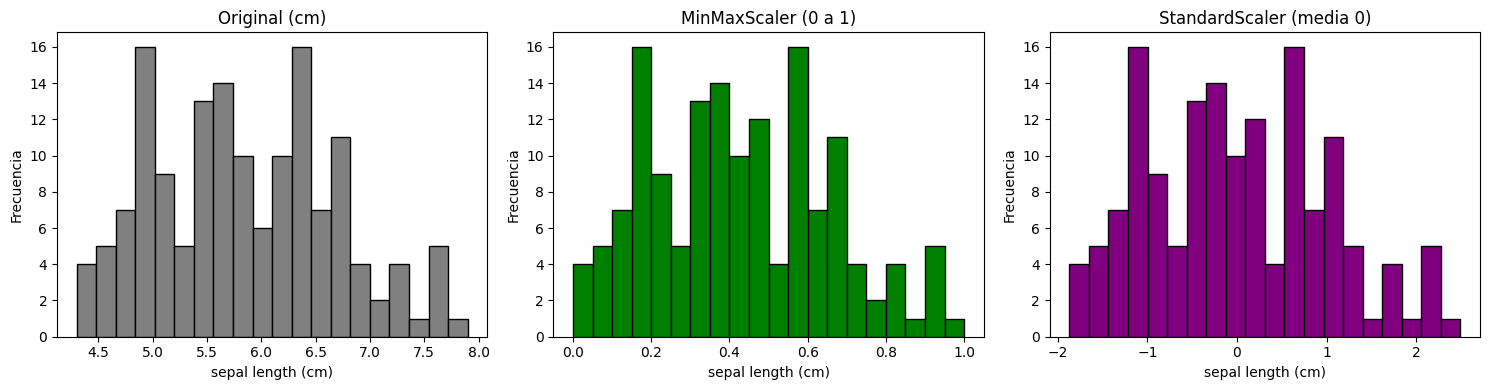

In [7]:
# Ejercicio 2: distribución de 'sepal length (cm)' antes y después del escalado
col = 'sepal length (cm)'
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(data[col], bins=20, color='gray', edgecolor='black')
axes[0].set_title('Original (cm)')

axes[1].hist(data_minmax[col], bins=20, color='green', edgecolor='black')
axes[1].set_title('MinMaxScaler (0 a 1)')

axes[2].hist(data_standard[col], bins=20, color='purple', edgecolor='black')
axes[2].set_title('StandardScaler (media 0)')

for ax in axes:
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

**Observación:** Las tres gráficas tienen exactamente la misma forma; lo único que cambia es la escala del eje horizontal. Los datos originales van de 4.3 a 7.9 cm, con MinMax quedan entre 0 y 1, y con StandardScaler quedan centrados en 0 (aprox. entre -2 y 2.5).
Esto muestra que el escalado no altera la distribución ni el orden de los datos, solo los transforma a una escala común.

### 3. Crea una gráfica de dispersión entre 'sepal length (cm)' y 'sepal width (cm)' con los datos escalados por StandardScaler.

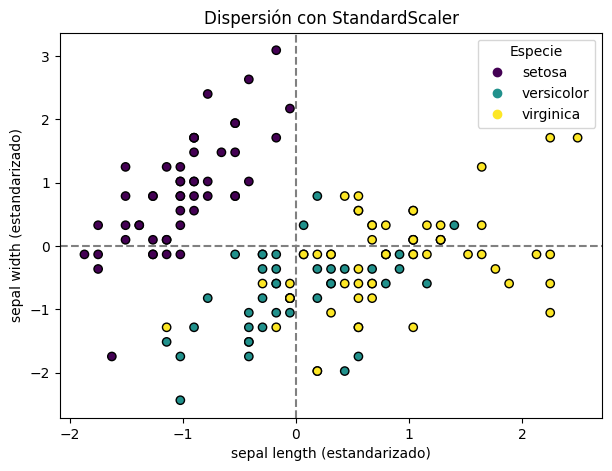

In [8]:
# Ejercicio 3: dispersión entre sepal length y sepal width (StandardScaler)
plt.figure(figsize=(7, 5))
grafica = plt.scatter(data_standard['sepal length (cm)'],
                      data_standard['sepal width (cm)'],
                      c=iris.target, cmap='viridis', edgecolor='black')

plt.xlabel('sepal length (estandarizado)')
plt.ylabel('sepal width (estandarizado)')
plt.title('Dispersión con StandardScaler')
plt.axhline(0, color='gray', linestyle='--')   # línea horizontal en la media (0)
plt.axvline(0, color='gray', linestyle='--')   # línea vertical en la media (0)
plt.legend(grafica.legend_elements()[0], iris.target_names, title='Especie')
plt.show()

**Observación:** Con StandardScaler ambas variables quedan centradas en 0, por lo que es fácil ver qué flores están por encima o por debajo del promedio.
La especie *setosa* forma un grupo separado (arriba a la izquierda): sépalos más cortos y anchos que el promedio. *Versicolor* y *virginica* se mezclan entre sí, con sépalos más largos y angostos.
En general no hay una relación fuerte entre el largo y el ancho del sépalo cuando se consideran todas las flores juntas.

### 4. ¿Qué técnica de escalado crees que es más adecuada para este conjunto de datos? ¿Por qué?

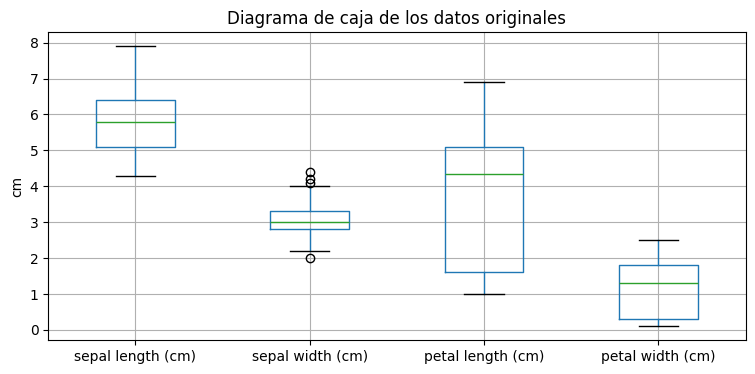

Valores atípicos por columna:
sepal length (cm)    0
sepal width (cm)     4
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [9]:
# Ejercicio 4: revisar valores atípicos para elegir el escalado
plt.figure(figsize=(9, 4))
data.boxplot()
plt.title('Diagrama de caja de los datos originales')
plt.ylabel('cm')
plt.show()

# Contar atípicos por columna usando el rango intercuartílico (IQR)
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
atipicos = ((data < Q1 - 1.5 * IQR) | (data > Q3 + 1.5 * IQR)).sum()
print("Valores atípicos por columna:")
print(atipicos)

**Respuesta:** Considero que **StandardScaler** es la técnica más adecuada para este conjunto de datos, por estas razones:
- El análisis de atípicos muestra que casi no hay valores extremos (solo 4 en 'sepal width'), y las distribuciones son relativamente simétricas, que es el caso ideal para StandardScaler.
- StandardScaler centra todas las variables en 0 con desviación estándar 1, lo que facilita comparar cada flor contra el promedio (como se vio en la gráfica de dispersión).
- Es menos sensible a valores atípicos que MinMaxScaler, que depende directamente del mínimo y el máximo.

Aun así, como todas las